In [ ]:
import matplotlib.pyplot as plt

import torch
import yaml
import json
import hashlib
import numpy as np
import pandas as pd
from tqdm import tqdm
from PIL import Image
from pathlib import Path

from torchvision import transforms

from src.utils.inference import *
from src.utils.dataset import *
from src.helper import (
    load_models_from_checkpoint,
    init_model_dinov3
)
from torch.optim.lr_scheduler import LinearLR, CosineAnnealingLR, SequentialLR
from transformers import ViTConfig, ViTModel


/home/vhondru/istoian/ijepa-anomaly-detection/.ijepa-venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
### To modify these configuration values
DATASET_NAME = "BraTS2021_slice"
EXPERIMENT_NAME = "enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training"
NUM_EPOCHS = 100
WARMUP_EPOCHS = 10
TRAIN_BATCH_SIZE = 64
START_LR = 1e-6
PEAK_LR = 1e-3
FINAL_LR = 1e-5
WEIGHT_DECAY = 0.05
###

In [3]:
def normalize(x, global_max, global_min):
    # Normalize weights to [0, 1] for visualization
    return (x - global_min) / (global_max - global_min)

def plot_filters(model):
    weights = model.embeddings.patch_embeddings.projection.weight
    global_max = torch.max(weights).detach().cpu()
    global_min = torch.min(weights).detach().cpu()

    # Let's look at the first 16 filters (out of 384)
    _, axes = plt.subplots(4, 4, figsize=(8, 8))
    for i, ax in enumerate(axes.flat):
        # Permute from [C, H, W] to [H, W, C] for plotting
        filter_img = weights[i].detach().cpu().permute(1, 2, 0)
        ax.imshow(normalize(x=filter_img, global_max=global_max, global_min=global_min))
        ax.axis('off')
        ax.set_title(f"Filter {i}")

    plt.show()    

In [ ]:
# Set up the device
if not torch.cuda.is_available():
    device = torch.device('cpu')
else:
    device = torch.device('cuda:0')
    torch.cuda.set_device(device)

In [ ]:
# Initializing a ViT model with a custom configuration
# 6 transformer blocks, 6 attention heads, 384 hidden size, mlp_ratio=4 
configuration = ViTConfig(
    hidden_size=384,
    num_hidden_layers=6,
    num_attention_heads=6,
    intermediate_size=1536
)

# Initializing a VIT model with random weights
student_model = ViTModel(configuration).to(device)

In [ ]:
configuration = student_model.config

for name, param in student_model.named_parameters():
    print(name)

embeddings.cls_token
embeddings.position_embeddings
embeddings.patch_embeddings.projection.weight
embeddings.patch_embeddings.projection.bias
encoder.layer.0.attention.attention.query.weight
encoder.layer.0.attention.attention.query.bias
encoder.layer.0.attention.attention.key.weight
encoder.layer.0.attention.attention.key.bias
encoder.layer.0.attention.attention.value.weight
encoder.layer.0.attention.attention.value.bias
encoder.layer.0.attention.output.dense.weight
encoder.layer.0.attention.output.dense.bias
encoder.layer.0.intermediate.dense.weight
encoder.layer.0.intermediate.dense.bias
encoder.layer.0.output.dense.weight
encoder.layer.0.output.dense.bias
encoder.layer.0.layernorm_before.weight
encoder.layer.0.layernorm_before.bias
encoder.layer.0.layernorm_after.weight
encoder.layer.0.layernorm_after.bias
encoder.layer.1.attention.attention.query.weight
encoder.layer.1.attention.attention.query.bias
encoder.layer.1.attention.attention.key.weight
encoder.layer.1.attention.attention

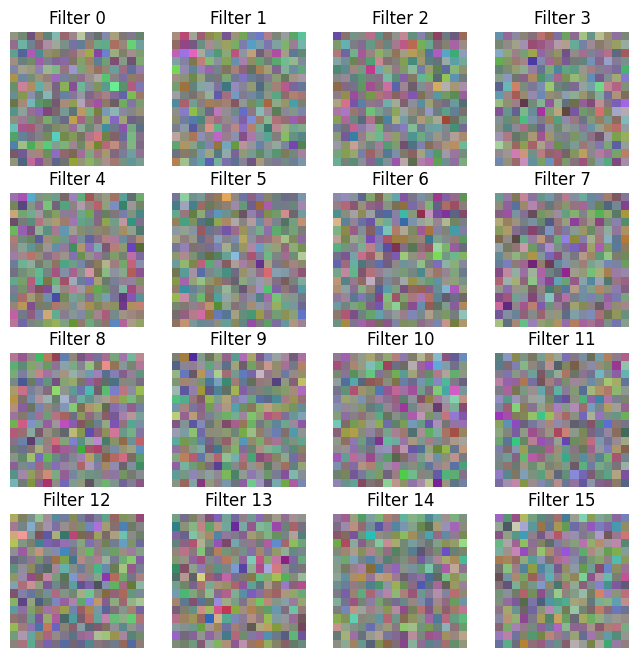

In [7]:
plot_filters(student_model)

In [8]:
weight_before = student_model.embeddings.patch_embeddings.projection.weight.clone().detach()
print(weight_before)

tensor([[[[ 7.5545e-03, -1.1286e-02, -1.5063e-02,  ..., -4.2344e-03,
           -3.3143e-03, -2.2549e-02],
          [ 1.0569e-02, -1.6270e-02, -1.6686e-02,  ...,  1.3542e-02,
           -2.0598e-02, -1.5244e-02],
          [-2.6512e-02, -3.4046e-02,  2.7966e-02,  ..., -3.9831e-03,
            2.2683e-02, -3.8686e-03],
          ...,
          [-3.7004e-02,  1.6525e-02, -4.3091e-02,  ...,  4.7327e-04,
           -1.4964e-03, -4.2259e-03],
          [-1.0665e-02, -1.2608e-02,  1.9109e-02,  ..., -9.6980e-03,
           -1.5324e-02,  6.5328e-03],
          [ 9.0361e-03, -3.9148e-02,  4.3377e-02,  ..., -1.2474e-02,
           -2.5960e-02, -9.3549e-03]],

         [[ 1.1619e-02,  2.2370e-03, -3.7496e-02,  ..., -1.0819e-02,
           -9.3310e-03, -1.5157e-03],
          [-1.7884e-02,  3.1843e-02, -2.2251e-03,  ...,  1.8784e-03,
            5.3743e-02,  1.9019e-02],
          [ 1.8281e-02, -2.4656e-02, -3.1390e-02,  ..., -4.6722e-03,
            4.3175e-03,  1.6681e-02],
          ...,
     

In [9]:
subpath_list = os.getcwd().split(os.sep)
root_directory_path = os.path.join(*subpath_list[:-1])
current_dir = subpath_list[-1]

TRAIN_DATASET_PATH = f"/media/vhondru/hdd/istoian/BMAD/dataset/{DATASET_NAME}/train"
VALID_DATASET_PATH = f"/media/vhondru/hdd/istoian/BMAD/dataset/{DATASET_NAME}/valid"

EXPERIMENT_FOLDER_PATH = (
    f"/{root_directory_path}/{current_dir}/"
    f"experiments_{DATASET_NAME}/{EXPERIMENT_NAME}/checkpoints_distilled_model"
)

os.makedirs(EXPERIMENT_FOLDER_PATH, exist_ok=True)

CONFIG_PATH = (
    f"/{root_directory_path}/{current_dir}/"
    f"experiments_{DATASET_NAME}/{EXPERIMENT_NAME}/logs/config_run.yaml"
)

CKPT_FOLDER_PATH = EXPERIMENT_FOLDER_PATH.replace(f"checkpoints_distilled_model", "checkpoints")
CKPT_FILE_PATH = f"{CKPT_FOLDER_PATH}/{EXPERIMENT_NAME}-latest.pth.tar"

In [10]:
with open(CONFIG_PATH, "r") as f:
    config = yaml.safe_load(f)

# Read the configuration file (which was used for training the target encoder)
# --- context encoder
encoder_model_name = config["meta"]["encoder_model_name"]
encoder_weights_path = config["meta"]["encoder_weights_source"]
encoder_embed_dim = config["meta"]["encoder_embed_dim"]

# --- target encoder
target_encoder_model_name = config["meta"]["target_encoder_model_name"]
target_encoder_weights_path = config["meta"]["target_encoder_weights_source"]

# --- predictor
predictor_depth = config["meta"]["predictor_depth"]
predictor_num_heads = config["meta"]["predictor_num_heads"]
predictor_embed_dim = config["meta"]["predictor_embed_dim"]

# --- data transforms
crop_size = config["data"]["crop_size"]
patch_size = config["mask"]["patch_size"]
count_border_pixels = config["data"]["count_border_pixels"]

# Init DinoV3/I-Jepa models: (context) encoder (DinoV3) + predictor (I-Jepa checkpoint) + target_encoder (DinoV3 - same architecture as the context encoder)
dict_models = init_model_dinov3(
    device=device,
    encoder_model_name=encoder_model_name,
    encoder_weights_path=encoder_weights_path,
    predictor_depth=predictor_depth,
    encoder_embed_dim=encoder_embed_dim,
    predictor_embed_dim=predictor_embed_dim,
    predictor_num_patches=(crop_size // patch_size) * (crop_size // patch_size),
    predictor_num_heads=predictor_num_heads,
    target_encoder_model_name=target_encoder_model_name,
    target_encoder_weights_path=target_encoder_weights_path
)
encoder = dict_models["encoder"]
predictor = dict_models["predictor"]
target_encoder = dict_models["target_encoder"]

# Load the pre-trained checkpoint (encoder + target encoder - DinoV3 VitS, predictor - IJepa checkpoint)
print(f"Loading checkpoint from: {CKPT_FILE_PATH}")
loaded_dict_from_checkpoint = load_models_from_checkpoint(
    checkpoint_path=CKPT_FILE_PATH,
    encoder=encoder,
    predictor=predictor,
    target_encoder=target_encoder,
    optimizer=None,
    scaler=None,
    dinov3_ckpt=True
)

target_encoder = loaded_dict_from_checkpoint["target_encoder"]

del loaded_dict_from_checkpoint

INFO:dinov3:using base=100 for rope new
INFO:dinov3:using min_period=None for rope new
INFO:dinov3:using max_period=None for rope new
INFO:dinov3:using normalize_coords=separate for rope new
INFO:dinov3:using shift_coords=None for rope new
INFO:dinov3:using rescale_coords=2 for rope new
INFO:dinov3:using jitter_coords=None for rope new
INFO:dinov3:using dtype=fp32 for rope new
INFO:dinov3:using mlp layer as FFN


Using cache found in /home/vhondru/.cache/torch/hub/facebookresearch_dinov3_main


INFO:root:Correctly initialized pretrained encoder (DinoV3 checkpoint)!
INFO:root:Correctly initialized pretrained predictor (to load the weights from an IJepa checkpoint)!
INFO:dinov3:using base=100 for rope new
INFO:dinov3:using min_period=None for rope new
INFO:dinov3:using max_period=None for rope new
INFO:dinov3:using normalize_coords=separate for rope new
INFO:dinov3:using shift_coords=None for rope new
INFO:dinov3:using rescale_coords=2 for rope new
INFO:dinov3:using jitter_coords=None for rope new
INFO:dinov3:using dtype=fp32 for rope new
INFO:dinov3:using mlp layer as FFN
INFO:root:Correctly initialized a pretrained target encoder (DinoV3 checkpoint)!
Loading checkpoint from: /home/vhondru/istoian/ijepa-anomaly-detection/experiments_BraTS2021_slice/enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training/checkpoints/enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training-latest.pth.tar
INFO:root:Loading the checkpoint 

Using cache found in /home/vhondru/.cache/torch/hub/facebookresearch_dinov3_main


INFO:root:Correctly loaded pretrained encoder from epoch 20 with msg: <All keys matched successfully>
INFO:root:Correctly loaded pretrained predictor from epoch 20 with msg: <All keys matched successfully>
INFO:root:Correctly loaded pretrained target encoder from epoch 20 with msg: <All keys matched successfully>
INFO:root:Correctly loaded the weights of the models from the checkpoint saved at the path: /home/vhondru/istoian/ijepa-anomaly-detection/experiments_BraTS2021_slice/enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training/checkpoints/enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training-latest.pth.tar


In [11]:
# Load the validation dataset
image_transform = transforms.Compose([
    transforms.Resize((crop_size, crop_size), Image.BICUBIC),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
])

train_dataset = ImageDataset(
    images_dir=TRAIN_DATASET_PATH,
    dataset_name=DATASET_NAME,
    count_border_pixels=count_border_pixels,
    transform=image_transform
)

train_loader = torch.utils.data.DataLoader(
    dataset=train_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    drop_last=False
)

valid_dataset = ImageDataset(
    images_dir=VALID_DATASET_PATH,
    dataset_name=DATASET_NAME,
    count_border_pixels=count_border_pixels,
    transform=image_transform
)

valid_loader = torch.utils.data.DataLoader(
    dataset=valid_dataset,
    batch_size=32,
    shuffle=False,
    drop_last=False
)

print("Number of training samples: ", len(train_dataset))
print("Number of training batches: ", len(train_loader))
print()
print("Number of validation samples: ", len(valid_dataset))
print("Number of validation batches: ", len(valid_loader))

Number of training samples:  7500
Number of training batches:  118

Number of validation samples:  83
Number of validation batches:  3


In [12]:
# Freeze the target encoder weights
for name, param in target_encoder.named_parameters():
    param.requires_grad = False

# Feed the trainable parameters of the student to the optimizer
trainable_params = [param for param in student_model.parameters() if param.requires_grad]
optimizer = torch.optim.AdamW(params=trainable_params, lr=PEAK_LR, weight_decay=WEIGHT_DECAY)
criterion = torch.nn.MSELoss()

# Learning rate schedulers
# Phase 1: Linear Warmup -> from 1e-6 (START_LR) up to 1e-3 (PEAK_LR)
warmup_sched = LinearLR(optimizer, start_factor=START_LR / PEAK_LR, total_iters=WARMUP_EPOCHS)

# Phase 2: Cosine Annealing -> from 1e-3 (PEAK_LR) down to 1e-5 (FINAL_LR)
cosine_sched = CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS - WARMUP_EPOCHS, eta_min=FINAL_LR)

scheduler = SequentialLR(
    optimizer, 
    schedulers=[warmup_sched, cosine_sched], 
    milestones=[WARMUP_EPOCHS]
)

In [13]:
for name, param in student_model.named_parameters():
    if param.requires_grad == True:
        print(name)

embeddings.cls_token
embeddings.position_embeddings
embeddings.patch_embeddings.projection.weight
embeddings.patch_embeddings.projection.bias
encoder.layer.0.attention.attention.query.weight
encoder.layer.0.attention.attention.query.bias
encoder.layer.0.attention.attention.key.weight
encoder.layer.0.attention.attention.key.bias
encoder.layer.0.attention.attention.value.weight
encoder.layer.0.attention.attention.value.bias
encoder.layer.0.attention.output.dense.weight
encoder.layer.0.attention.output.dense.bias
encoder.layer.0.intermediate.dense.weight
encoder.layer.0.intermediate.dense.bias
encoder.layer.0.output.dense.weight
encoder.layer.0.output.dense.bias
encoder.layer.0.layernorm_before.weight
encoder.layer.0.layernorm_before.bias
encoder.layer.0.layernorm_after.weight
encoder.layer.0.layernorm_after.bias
encoder.layer.1.attention.attention.query.weight
encoder.layer.1.attention.attention.query.bias
encoder.layer.1.attention.attention.key.weight
encoder.layer.1.attention.attention

In [14]:
print(f"Started training for {NUM_EPOCHS} epochs...")

train_loss_per_epoch = []
valid_loss_per_epoch = []

for epoch in range(NUM_EPOCHS):
    print('Epoch %d' % epoch)
    train_losses = []

    student_model.train()
    target_encoder.eval()
    for train_batch_idx, (image, _, _) in enumerate(train_loader):
        image = image.to(device)
        with torch.no_grad():
            # --- Target encoder forward prop
            target_encoder_emb = target_encoder(image)

        # [CLS] token -> position 0; 
        student_emb = student_model(image).last_hidden_state[:, 1: , :]

        assert target_encoder_emb.shape == student_emb.shape

        optimizer.zero_grad()
        loss = criterion(student_emb, target_encoder_emb)
        loss.backward()
        optimizer.step()

        loss_value = loss.detach().cpu().item()
        train_losses.append(loss_value)
        if train_batch_idx % 20 == 0:
            print(f"Train loss batch index {train_batch_idx}: {loss_value}")

    avg_train_loss_crt_epoch = np.mean(train_losses)
    train_loss_per_epoch.append(avg_train_loss_crt_epoch)
    print(f"Average train loss epoch {epoch} = {avg_train_loss_crt_epoch}")

    print("Computing the performance on the validation set...")

    student_model.eval()
    target_encoder.eval()

    valid_losses = []
    for valid_batch_idx, (image, _, _) in enumerate(valid_loader):
        image = image.to(device)

        with torch.no_grad():
            # --- Target encoder forward prop
            target_encoder_emb = target_encoder(image)
            student_emb = student_model(image).last_hidden_state[:, 1: , :]

            assert target_encoder_emb.shape == student_emb.shape

            valid_loss = criterion(student_emb, target_encoder_emb).detach().cpu().item()
            valid_losses.append(valid_loss)

            print(f"Valid loss batch index {valid_batch_idx}: {valid_loss}")

    avg_valid_loss_crt_epoch = np.mean(valid_losses)
    print(f"Average validation loss epoch {epoch} = {avg_valid_loss_crt_epoch}")
    valid_loss_per_epoch.append(avg_valid_loss_crt_epoch)

    scheduler.step()

Started training for 100 epochs...
Epoch 0


Train loss batch index 0: 1.2765920162200928
Train loss batch index 20: 1.2210042476654053
Train loss batch index 40: 1.1737886667251587
Train loss batch index 60: 1.1355981826782227
Train loss batch index 80: 1.0693224668502808
Train loss batch index 100: 1.0079249143600464
Average train loss epoch 0 = 1.1233278563467122
Computing the performance on the validation set...
Valid loss batch index 0: 0.9888433218002319
Valid loss batch index 1: 0.9945076704025269
Valid loss batch index 2: 0.9988443851470947
Average validation loss epoch 0 = 0.9940651257832845
Epoch 1
Train loss batch index 0: 0.9978498220443726
Train loss batch index 20: 0.47184592485427856
Train loss batch index 40: 0.4195515215396881
Train loss batch index 60: 0.39668548107147217
Train loss batch index 80: 0.36422833800315857
Train loss batch index 100: 0.31680020689964294
Average train loss epoch 1 = 0.4047961970001964
Computing the performance on the validation set...
Valid loss batch index 0: 0.34316328167915344
Vali

<Axes: xlabel='epoch', ylabel='loss'>

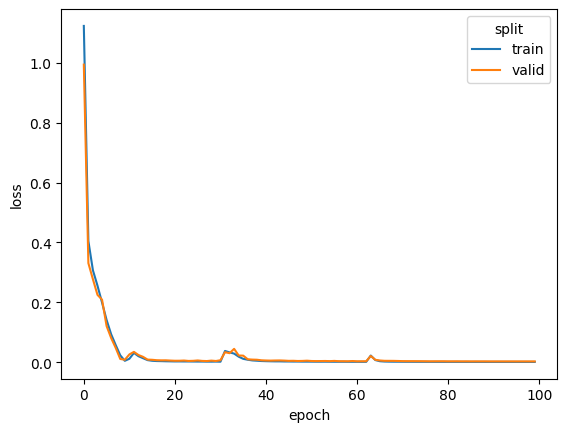

In [15]:
import seaborn as sns
import pandas as pd

loss_df = pd.DataFrame(
    {
        "epoch": [i for i in range(NUM_EPOCHS)] + [i for i in range(NUM_EPOCHS)],
        "loss": train_loss_per_epoch + valid_loss_per_epoch,
        "split": ["train"] * NUM_EPOCHS + ["valid"] * NUM_EPOCHS
    }
)
sns.lineplot(loss_df, x="epoch", y="loss", hue="split")

In [16]:
print(student_model.embeddings.patch_embeddings.projection.weight)

Parameter containing:
tensor([[[[ 1.0829e-02, -2.7318e-03, -1.4995e-02,  ..., -1.8451e-03,
            4.8102e-04, -1.3846e-02],
          [ 1.9066e-02, -6.0770e-03, -2.1744e-02,  ...,  1.2340e-02,
           -1.8313e-02, -1.3197e-02],
          [-1.0367e-02, -2.4813e-02,  3.5253e-03,  ..., -5.2338e-03,
            1.0832e-02, -5.3028e-03],
          ...,
          [-3.5033e-02,  3.9182e-03, -3.2175e-02,  ..., -1.2978e-02,
           -6.4163e-03, -5.1577e-03],
          [-1.0224e-02, -1.0122e-02,  1.7498e-02,  ..., -1.7174e-02,
           -1.6602e-02,  3.9116e-03],
          [ 5.0931e-03, -3.0408e-02,  2.7752e-02,  ..., -1.3812e-02,
           -2.0582e-02, -6.5240e-03]],

         [[ 2.0405e-02,  1.5384e-02, -2.7470e-02,  ..., -5.8672e-03,
           -1.9009e-03,  6.6116e-03],
          [ 5.6955e-03,  3.6033e-02, -9.9124e-03,  ...,  3.1919e-03,
            3.7198e-02,  1.6117e-02],
          [ 2.8190e-02, -1.7377e-02, -4.4352e-02,  ..., -9.3702e-03,
           -4.7762e-03,  1.2363e-02]

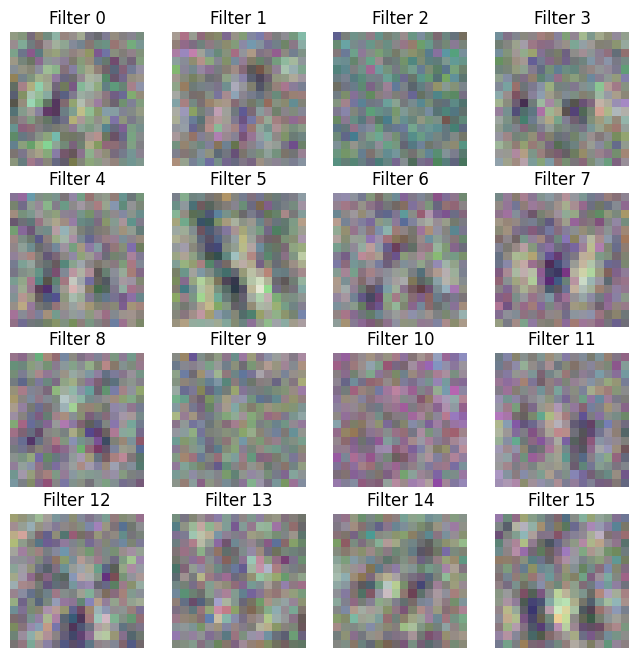

In [17]:
plot_filters(student_model)

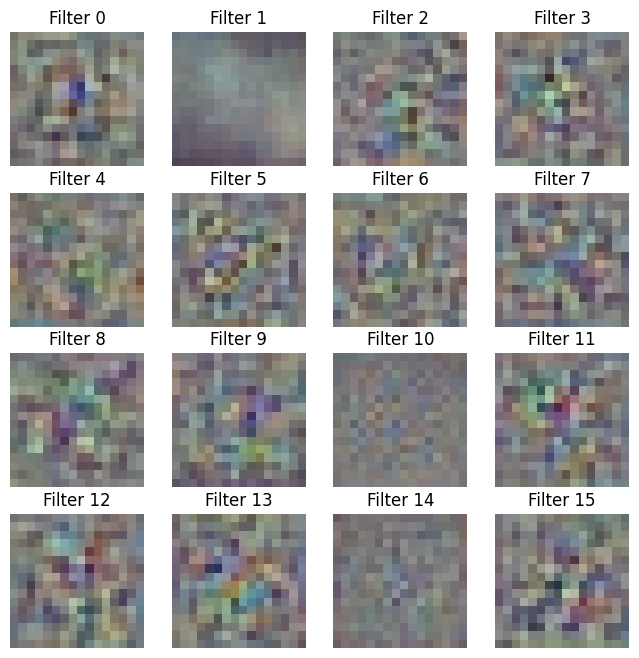

In [18]:
weights = target_encoder.patch_embed.proj.weight
# Let's look at the first 16 filters (out of 384)
global_max = torch.max(weights).detach().cpu()
global_min = torch.min(weights).detach().cpu()

_, axes = plt.subplots(4, 4, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    # Permute from [C, H, W] to [H, W, C] for plotting
    filter_img = weights[i + 16].detach().cpu().permute(1, 2, 0)
    ax.imshow(normalize(filter_img, global_max=global_max, global_min=global_min))
    ax.axis('off')
    ax.set_title(f"Filter {i}")

plt.show()

In [19]:
student_model.embeddings.patch_embeddings.projection.weight.requires_grad

True

In [20]:
for i in range(16):
    change = (student_model.embeddings.patch_embeddings.projection.weight - weight_before).abs()[i].mean()
    print(change)

tensor(0.0121, device='cuda:0', grad_fn=<MeanBackward0>)
tensor(0.0111, device='cuda:0', grad_fn=<MeanBackward0>)
tensor(0.0117, device='cuda:0', grad_fn=<MeanBackward0>)
tensor(0.0113, device='cuda:0', grad_fn=<MeanBackward0>)
tensor(0.0117, device='cuda:0', grad_fn=<MeanBackward0>)
tensor(0.0183, device='cuda:0', grad_fn=<MeanBackward0>)
tensor(0.0106, device='cuda:0', grad_fn=<MeanBackward0>)
tensor(0.0125, device='cuda:0', grad_fn=<MeanBackward0>)
tensor(0.0107, device='cuda:0', grad_fn=<MeanBackward0>)
tensor(0.0059, device='cuda:0', grad_fn=<MeanBackward0>)
tensor(0.0101, device='cuda:0', grad_fn=<MeanBackward0>)
tensor(0.0110, device='cuda:0', grad_fn=<MeanBackward0>)
tensor(0.0141, device='cuda:0', grad_fn=<MeanBackward0>)
tensor(0.0116, device='cuda:0', grad_fn=<MeanBackward0>)
tensor(0.0112, device='cuda:0', grad_fn=<MeanBackward0>)
tensor(0.0160, device='cuda:0', grad_fn=<MeanBackward0>)


In [21]:
student_model.embeddings.patch_embeddings.projection.weight

Parameter containing:
tensor([[[[ 1.0829e-02, -2.7318e-03, -1.4995e-02,  ..., -1.8451e-03,
            4.8102e-04, -1.3846e-02],
          [ 1.9066e-02, -6.0770e-03, -2.1744e-02,  ...,  1.2340e-02,
           -1.8313e-02, -1.3197e-02],
          [-1.0367e-02, -2.4813e-02,  3.5253e-03,  ..., -5.2338e-03,
            1.0832e-02, -5.3028e-03],
          ...,
          [-3.5033e-02,  3.9182e-03, -3.2175e-02,  ..., -1.2978e-02,
           -6.4163e-03, -5.1577e-03],
          [-1.0224e-02, -1.0122e-02,  1.7498e-02,  ..., -1.7174e-02,
           -1.6602e-02,  3.9116e-03],
          [ 5.0931e-03, -3.0408e-02,  2.7752e-02,  ..., -1.3812e-02,
           -2.0582e-02, -6.5240e-03]],

         [[ 2.0405e-02,  1.5384e-02, -2.7470e-02,  ..., -5.8672e-03,
           -1.9009e-03,  6.6116e-03],
          [ 5.6955e-03,  3.6033e-02, -9.9124e-03,  ...,  3.1919e-03,
            3.7198e-02,  1.6117e-02],
          [ 2.8190e-02, -1.7377e-02, -4.4352e-02,  ..., -9.3702e-03,
           -4.7762e-03,  1.2363e-02]

In [22]:
weight_before

tensor([[[[ 7.5545e-03, -1.1286e-02, -1.5063e-02,  ..., -4.2344e-03,
           -3.3143e-03, -2.2549e-02],
          [ 1.0569e-02, -1.6270e-02, -1.6686e-02,  ...,  1.3542e-02,
           -2.0598e-02, -1.5244e-02],
          [-2.6512e-02, -3.4046e-02,  2.7966e-02,  ..., -3.9831e-03,
            2.2683e-02, -3.8686e-03],
          ...,
          [-3.7004e-02,  1.6525e-02, -4.3091e-02,  ...,  4.7327e-04,
           -1.4964e-03, -4.2259e-03],
          [-1.0665e-02, -1.2608e-02,  1.9109e-02,  ..., -9.6980e-03,
           -1.5324e-02,  6.5328e-03],
          [ 9.0361e-03, -3.9148e-02,  4.3377e-02,  ..., -1.2474e-02,
           -2.5960e-02, -9.3549e-03]],

         [[ 1.1619e-02,  2.2370e-03, -3.7496e-02,  ..., -1.0819e-02,
           -9.3310e-03, -1.5157e-03],
          [-1.7884e-02,  3.1843e-02, -2.2251e-03,  ...,  1.8784e-03,
            5.3743e-02,  1.9019e-02],
          [ 1.8281e-02, -2.4656e-02, -3.1390e-02,  ..., -4.6722e-03,
            4.3175e-03,  1.6681e-02],
          ...,
     

In [23]:
distillation_config = {}
distillation_config["DATASET_NAME"] = DATASET_NAME
distillation_config["EXPERIMENT_NAME"] = EXPERIMENT_NAME
distillation_config["NUM_EPOCHS"] = NUM_EPOCHS
distillation_config["WARMUP_EPOCHS"] = WARMUP_EPOCHS
distillation_config["TRAIN_BATCH_SIZE"] = TRAIN_BATCH_SIZE
distillation_config["START_LR"] = START_LR
distillation_config["PEAK_LR"] = PEAK_LR
distillation_config["FINAL_LR"] = FINAL_LR
distillation_config["WEIGHT_DECAY"] = WEIGHT_DECAY

# Sort the dictionary by the keys
distillation_config_sorted = sorted([(field, value) for field, value in distillation_config.items()], key=lambda x: x[0], reverse=False)
print(distillation_config_sorted)

distillation_config_hash = hashlib.sha256(json.dumps(distillation_config_sorted).encode()).hexdigest()[: 16]
print(distillation_config_hash)

[('DATASET_NAME', 'BraTS2021_slice'), ('EXPERIMENT_NAME', 'enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training'), ('FINAL_LR', 1e-05), ('NUM_EPOCHS', 100), ('PEAK_LR', 0.001), ('START_LR', 1e-06), ('TRAIN_BATCH_SIZE', 64), ('WARMUP_EPOCHS', 10), ('WEIGHT_DECAY', 0.05)]
a5bd70b66a814550


In [ ]:
distillation_model_path = os.path.join(EXPERIMENT_FOLDER_PATH, f"{distillation_config_hash}_student_model.pth")
torch.save(student_model.state_dict(), distillation_model_path)

distillation_optimizer_path = os.path.join(EXPERIMENT_FOLDER_PATH, f"{distillation_config_hash}_optimizer.pth")
torch.save(optimizer.state_dict(), distillation_optimizer_path)

distillation_config_path = os.path.join(EXPERIMENT_FOLDER_PATH, f"{distillation_config_hash}_config.json")
with open(distillation_config_path, "w") as f:
    json.dump(distillation_config, f)

In [25]:
for name, _ in target_encoder.named_parameters():
    print(name)

cls_token
storage_tokens
mask_token
patch_embed.proj.weight
patch_embed.proj.bias
blocks.0.norm1.weight
blocks.0.norm1.bias
blocks.0.attn.qkv.weight
blocks.0.attn.qkv.bias
blocks.0.attn.proj.weight
blocks.0.attn.proj.bias
blocks.0.ls1.gamma
blocks.0.norm2.weight
blocks.0.norm2.bias
blocks.0.mlp.fc1.weight
blocks.0.mlp.fc1.bias
blocks.0.mlp.fc2.weight
blocks.0.mlp.fc2.bias
blocks.0.ls2.gamma
blocks.1.norm1.weight
blocks.1.norm1.bias
blocks.1.attn.qkv.weight
blocks.1.attn.qkv.bias
blocks.1.attn.proj.weight
blocks.1.attn.proj.bias
blocks.1.ls1.gamma
blocks.1.norm2.weight
blocks.1.norm2.bias
blocks.1.mlp.fc1.weight
blocks.1.mlp.fc1.bias
blocks.1.mlp.fc2.weight
blocks.1.mlp.fc2.bias
blocks.1.ls2.gamma
blocks.2.norm1.weight
blocks.2.norm1.bias
blocks.2.attn.qkv.weight
blocks.2.attn.qkv.bias
blocks.2.attn.proj.weight
blocks.2.attn.proj.bias
blocks.2.ls1.gamma
blocks.2.norm2.weight
blocks.2.norm2.bias
blocks.2.mlp.fc1.weight
blocks.2.mlp.fc1.bias
blocks.2.mlp.fc2.weight
blocks.2.mlp.fc2.bias
b

In [27]:
student_model.embeddings.patch_embeddings.projection.weight.shape

torch.Size([384, 3, 16, 16])

In [28]:
target_encoder.patch_embed.proj.weight.shape

torch.Size([384, 3, 16, 16])

In [ ]:
# Loading the saved model

configuration = ViTConfig(
    hidden_size=384,
    num_hidden_layers=6,
    num_attention_heads=6,
    intermediate_size=1536
)

# Initializing a model (with random weights) from the vit-base-patch16-224 style configuration
trained_student_model = ViTModel(configuration).to(device)
trained_student_model.load_state_dict(torch.load(distillation_model_path, weights_only=True))

<All keys matched successfully>

In [31]:
student_model.embeddings.patch_embeddings.projection.weight

Parameter containing:
tensor([[[[ 1.0829e-02, -2.7318e-03, -1.4995e-02,  ..., -1.8451e-03,
            4.8102e-04, -1.3846e-02],
          [ 1.9066e-02, -6.0770e-03, -2.1744e-02,  ...,  1.2340e-02,
           -1.8313e-02, -1.3197e-02],
          [-1.0367e-02, -2.4813e-02,  3.5253e-03,  ..., -5.2338e-03,
            1.0832e-02, -5.3028e-03],
          ...,
          [-3.5033e-02,  3.9182e-03, -3.2175e-02,  ..., -1.2978e-02,
           -6.4163e-03, -5.1577e-03],
          [-1.0224e-02, -1.0122e-02,  1.7498e-02,  ..., -1.7174e-02,
           -1.6602e-02,  3.9116e-03],
          [ 5.0931e-03, -3.0408e-02,  2.7752e-02,  ..., -1.3812e-02,
           -2.0582e-02, -6.5240e-03]],

         [[ 2.0405e-02,  1.5384e-02, -2.7470e-02,  ..., -5.8672e-03,
           -1.9009e-03,  6.6116e-03],
          [ 5.6955e-03,  3.6033e-02, -9.9124e-03,  ...,  3.1919e-03,
            3.7198e-02,  1.6117e-02],
          [ 2.8190e-02, -1.7377e-02, -4.4352e-02,  ..., -9.3702e-03,
           -4.7762e-03,  1.2363e-02]